In [3]:
%matplotlib inline
import os
import sys

# Move up one directory level from /notebooks to the workspace root
workspace_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

if workspace_root not in sys.path:
    sys.path.append(workspace_root)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd

import astropy.io.fits as pyfits
import astropy.units as u


import grizli
from grizli import utils
print(f'grizli version: {grizli.__version__}')

import msaexp
import msaexp.spectrum
print(f'msaexp version: {msaexp.__version__}')

BASE_URL = 'https://s3.amazonaws.com/msaexp-nirspec/extractions/'
PATH_TO_FILE = BASE_URL + '{root}/{file}'

from utils.fitting import line_cont_fit
from utils.spectrum_management import (resampling_spectra, weighted_average)


Halpha = {
    'element': r'3H\alpha, [NII] \lambda 6548, [NII] \lambda 6583',
    'rest_AA': [6564 * u.AA, 6548 * u.AA, 6583 * u.AA], 
    'sigma': 7.5, 
    'amplitude': [1 * 1e-18, 0.05* 1e-18, 0.07* 1e-18]   # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

Sii = {
    'element': r'2[SII] \lambda 6717, [SII] \lambda 6731',
    'rest_AA': [6717 * u.AA, 6731 * u.AA], 
    'sigma': 7.5, 
    'amplitude': [0.1* 1e-18, 0.09* 1e-18]  # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

Oiii1 = {
    'element': r'1[OIII] \lambda 4959',
    'rest_AA': 4959 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.35 * 1e-18  # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

Oiii2 = {
    'element': r'1[OIII] \lambda 5007',
    'rest_AA': 5007 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 1.4 * 1e-18  # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

Hbeta = {
    'element': r'1H \beta',
    'rest_AA': 4861 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.2 * 1e-18  # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

Oii = {
    'element': r'1[OIII] \lambda 3727',
    'rest_AA': 3727 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.3 * 1e-18  # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

Oi = {
    'element': r'1[OI] \lambda 6300',
    'rest_AA': 6300 * u.AA, 
    'sigma': 7.5, 
    'amplitude': 0.04 * 1e-18  # La amplitud inicial es lo unico que cambia si se transforma antes o despues de fittear
}

lines = [Halpha, Hbeta, Oi, Oii, Oiii1, Oiii2, Sii]

grizli version: 1.14.2
msaexp version: 0.9.17


https://grizli-cutout.herokuapp.com/nirspec_extractions?file=aurora-gdn02-v4_g235m-f170lp_1914_931951.spec.fits&output=csv
aurora-gdn02-v4_g140m-f100lp_1914_931951.spec.fits (True) 2.4832  grade=3
aurora-gdn02-v4_g235m-f170lp_1914_931951.spec.fits (True) 2.4832  grade=3
aurora-gdn02-v4_g395m-f290lp_1914_931951.spec.fits (True) 2.4832  grade=3
3H\alpha, [NII] \lambda 6548, [NII] \lambda 6583


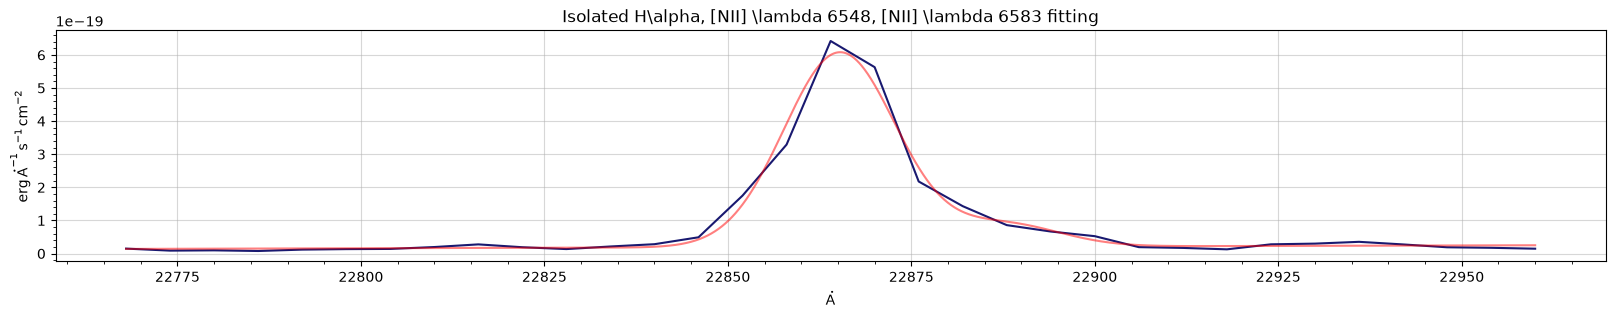

1H \beta


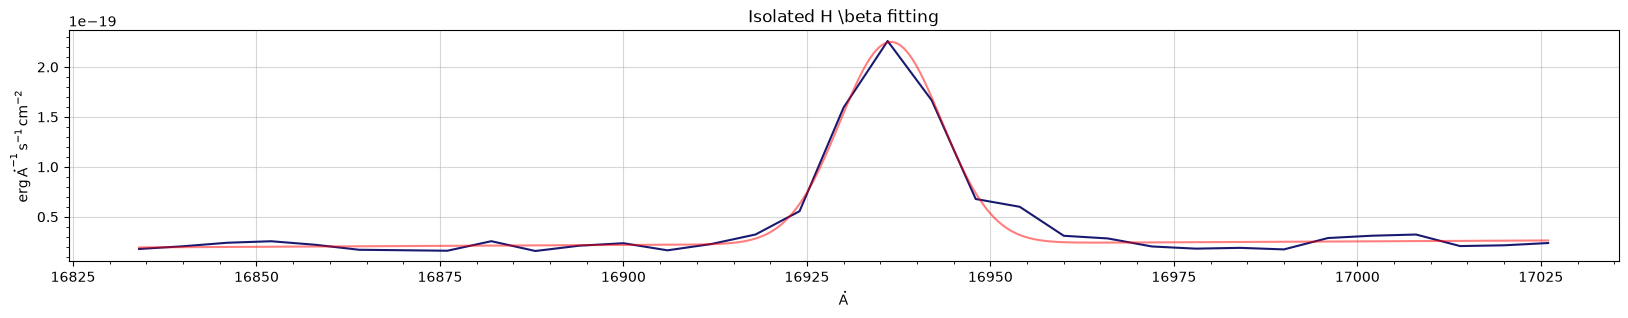

1[OI] \lambda 6300


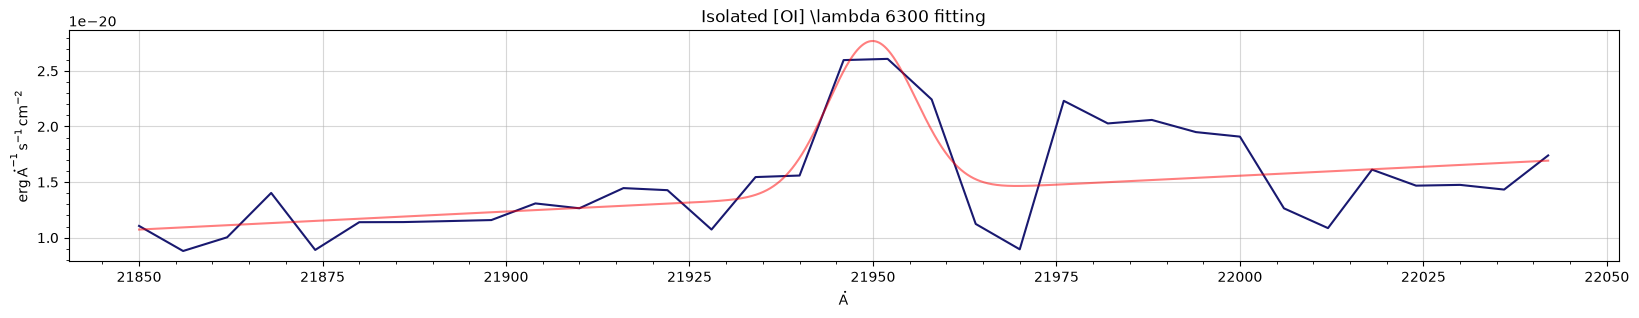

1[OIII] \lambda 3727


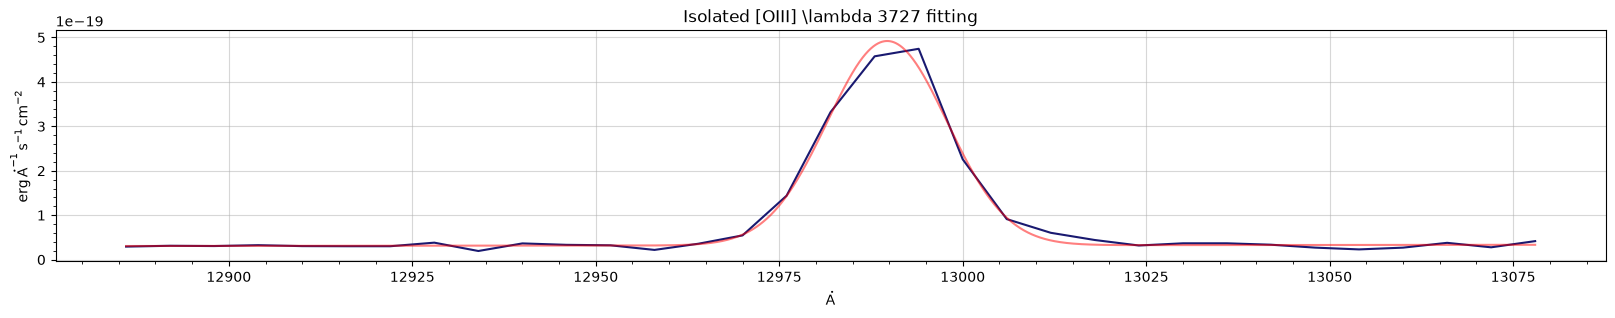

1[OIII] \lambda 4959


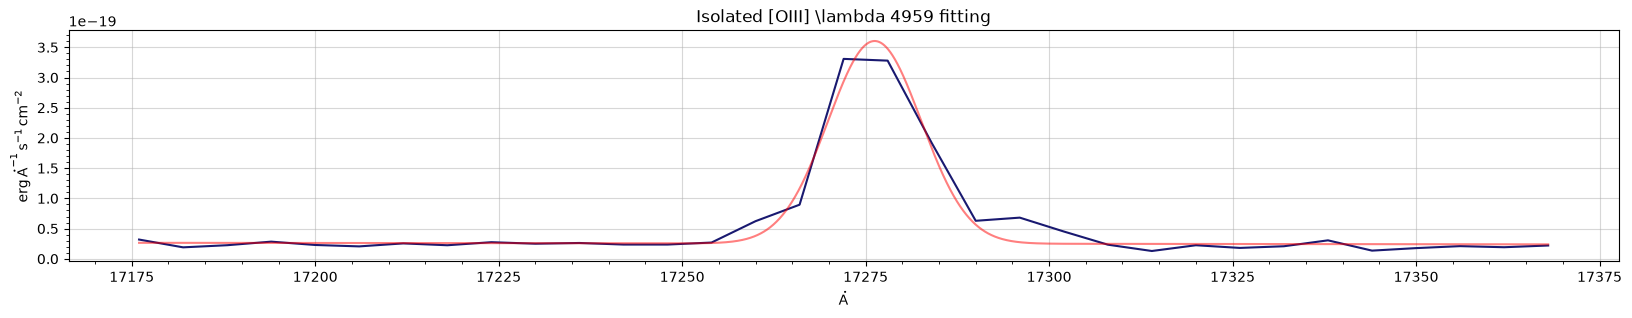

1[OIII] \lambda 5007


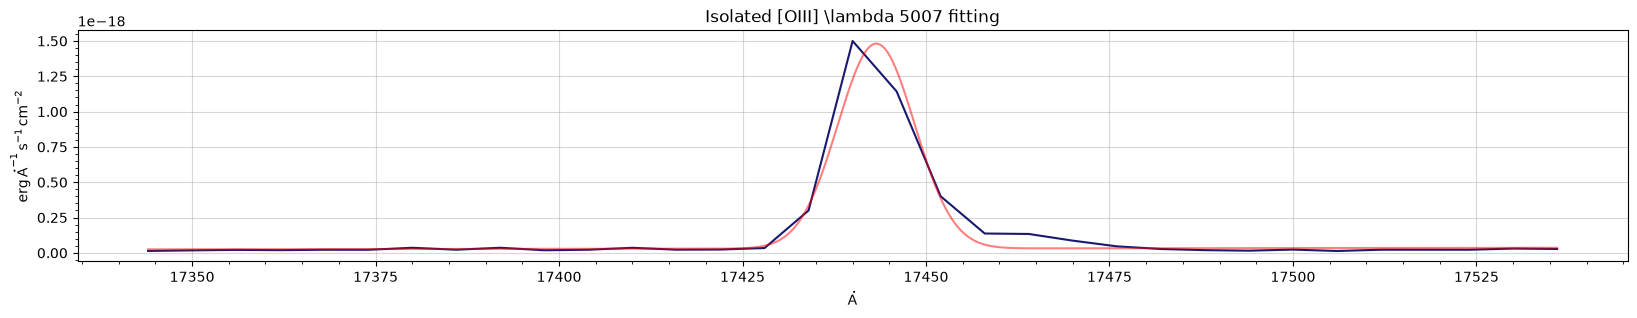

2[SII] \lambda 6717, [SII] \lambda 6731


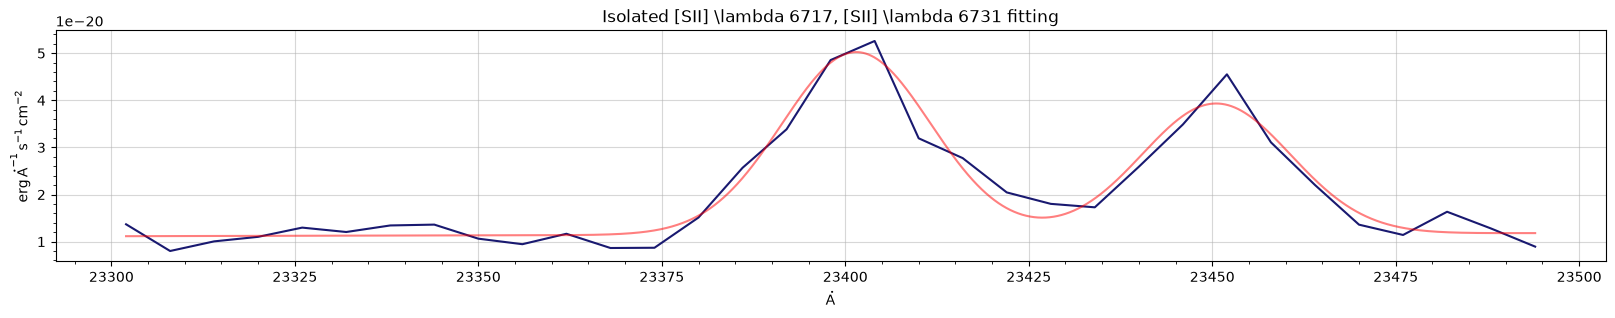

In [4]:
resampled_931951 = resampling_spectra("aurora-gdn02-v4_g235m-f170lp_1914_931951.spec.fits")

averaged_931951 = weighted_average(resampled_931951)

fits = {}
fluxes = {}

for line in lines:
    optimal, opterrs = line_cont_fit(averaged_931951, line)
    fits[optimal['element']] = [optimal, opterrs]
    if optimal['lines'] == '1':
        fluxes[optimal['element']] = optimal['flux1'] * 1e20
    elif optimal['lines'] == '2':
        fluxes[optimal['element']] = [optimal['flux1'] * 1e20, optimal['flux2'] * 1e20]
    elif optimal['lines'] == '3':
        fluxes[optimal['element']] = [optimal['flux1'] * 1e20, optimal['flux2'] * 1e20, optimal['flux3'] * 1e20]

In [5]:
display(fluxes)

{'H\\alpha, [NII] \\lambda 6548, [NII] \\lambda 6583': [1123.0841926552368,
  131.84716428670095,
  -3.3914030832414603],
 'H \\beta': 350.71800110208284,
 '[OI] \\lambda 6300': 20.600354742085457,
 '[OIII] \\lambda 3727': 938.4043745866842,
 '[OIII] \\lambda 4959': 532.5446784041433,
 '[OIII] \\lambda 5007': 1901.261158306975,
 '[SII] \\lambda 6717, [SII] \\lambda 6731': [98.48599792530887,
  70.32362430898387]}